#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy
from src.summary import summary

In [ ]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252
returns_array = np.array(returns)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

In [4]:
momentum_results

{'total_return': 5.400420064850694,
 'cagr': np.float64(0.07510187343734454),
 'annual_volatility': np.float64(0.12881047224381842),
 'annual_sharpe': np.float64(0.6270238991683582),
 'max_drawdown': np.float64(-0.3158124029521421),
 'calmar': np.float64(0.23780533232801945),
 'time_invested': np.float64(0.7752321981424148),
 'trades': np.int64(89)}

#### Exposure & Trade-Count Matched Strategy

In [5]:
def generate_random_signal_v4(prices, lookback):

    valid_days = len(prices) - lookback - 1

    time_invested = momentum_results["time_invested"]

    invested_days = round(valid_days * time_invested)
    cash_days = valid_days - invested_days

    invested_trade_days = np.random.choice(np.arange(1, invested_days), size = 44, replace = False)
    invested_trade_days = np.sort(invested_trade_days)
    
    invested_runs = [invested_trade_days[0]]
    
    for i in range(1,len(invested_trade_days)):
    
        run_length = invested_trade_days[i] - invested_trade_days[i - 1]
        invested_runs.append(run_length)
    
    invested_runs.append(invested_days - invested_trade_days[-1])
    
    
    cash_trade_days = np.random.choice(np.arange(1, cash_days), size = 44, replace = False)
    cash_trade_days = np.sort(cash_trade_days)
    
    cash_runs = [cash_trade_days[0]]
    
    for i in range(1,len(cash_trade_days)):
    
        run_length = cash_trade_days[i] - cash_trade_days[i - 1]
        cash_runs.append(run_length)
    
    cash_runs.append(cash_days - cash_trade_days[-1])
    
    sequence = []
    
    for i in range(len(cash_runs)):
    
        sequence.extend([0] * cash_runs[i])
        sequence.extend([1] * invested_runs[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal
    
    

In [6]:
def run_simulation_v4(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v4(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [7]:
np.random.seed(44)

simulation_output = run_simulation_v4(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,4.169497,0.066181,0.162721,0.475374,-0.428958,0.154284,0.775232,89
1,5.254369,0.074134,0.162634,0.521222,-0.422528,0.175454,0.775232,89
2,7.556949,0.087349,0.160339,0.602569,-0.378351,0.230869,0.775232,89
3,4.900737,0.071698,0.174828,0.483541,-0.541605,0.132381,0.775232,89
4,2.851770,0.054014,0.170531,0.393835,-0.564419,0.095698,0.775232,89
...,...,...,...,...,...,...,...,...
995,2.267030,0.047265,0.172530,0.354035,-0.571769,0.082665,0.775232,89
996,3.395293,0.059455,0.176037,0.416134,-0.539773,0.110148,0.775232,89
997,5.137488,0.073344,0.168858,0.503680,-0.411811,0.178101,0.775232,89
998,4.897402,0.071675,0.179142,0.476034,-0.512847,0.139758,0.775232,89


Sharpe Average: 0.4704
Sharpe Median:  0.4663
Largest Sharpe: 0.8063
Average No. of Trades: 89.0000
Average Time Invested: 0.7752
Empirical p-value: 0.048


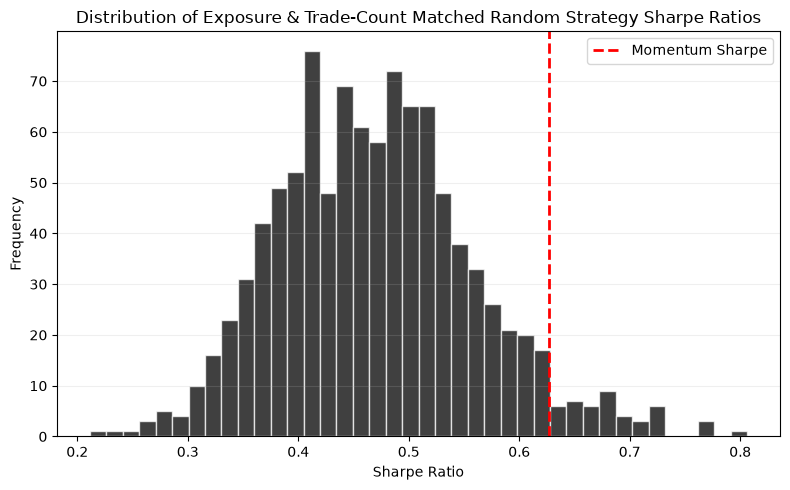

In [8]:
summary(simulation_df, momentum_results, "Distribution of Exposure & Trade-Count Matched Random Strategy Sharpe Ratios")